# jacscanomaly quickstart

One light curve is one `Event`; each step is a method and the results stay on it.
The data are a simulated Roman event (`example_data.npy`: time, flux, flux error).

In [1]:
import numpy as np
from jacscanomaly import Event, FinderConfig

time, flux, ferr = np.load("example_data.npy").T  # time is JD - 2450000
config = FinderConfig(parallax_time_offset=2450000.0)
ev = Event(time, flux, ferr, ra_deg=268.4, dec_deg=-29.2, config=config)

## 1. Fit a single lens and scan the residual

The scan looks for short bumps and dips; a detection has `score >= 10`.

In [2]:
ev.fit("pspl")

Fit(model='pspl', params={'t0': 9826.560714021854, 'tE': 8.616003538088025, 'u0': 0.3532817994846128}, fs=9.661792787384348e-10, fb=1.5384043218522003e-09, chi2=40468.93111514455, J=np.float64(40521.98133724458))

In [3]:
pspl_scan = ev.scan()
pspl_scan.detected, [(round(c.t0, 3), round(c.teff, 3), round(c.score, 1)) for c in pspl_scan.detections]

(True, [(9826.001, 0.3, 55.0)])

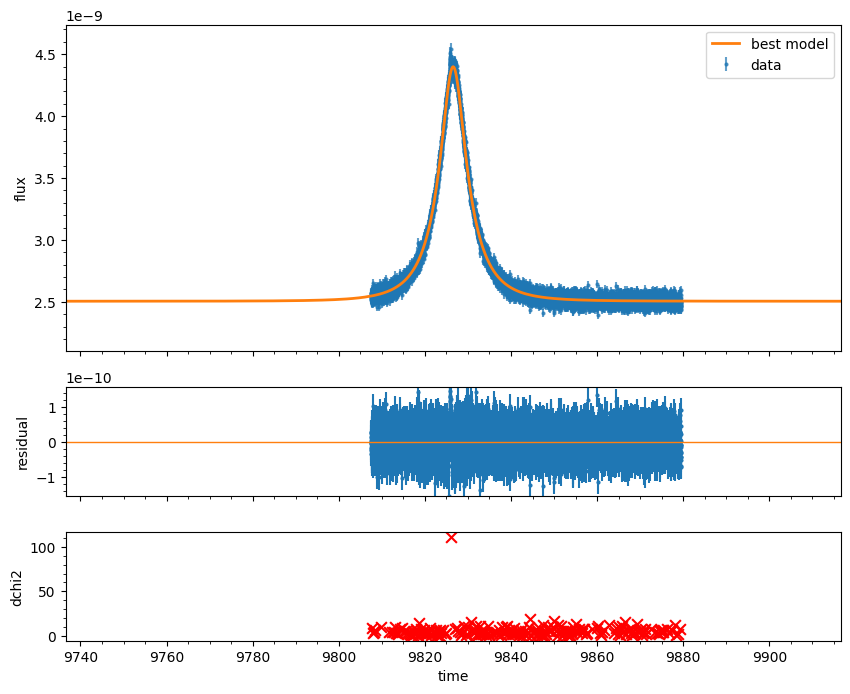

In [4]:
ev.plot_result("pspl");

## 2. Try the single-lens effects

A finite source or annual parallax can make a short deviation too. Refit with each and scan again.

In [5]:
ev.fit("fspl", start="pspl")
fspl_scan = ev.scan()
ev.fit("parallax", start="pspl")
parallax_scan = ev.scan()
fspl_scan.detected, parallax_scan.detected

(True, True)

## 3. Fit the anomaly

Neither explains it, so the host is fitted together with the anomaly ("atoms").
Each feature is one anomaly window: shape, peak time, FWHM, the `dchi2` it explains.

In [6]:
for model in ("pspl", "fspl", "parallax"):
    ev.fit_atoms(model)

ev.atoms["pspl"].features[0]

Feature(candidate=Candidate(t_start=9825.101724705486, t_end=9826.89969452716, t0=None, label=None), kind='bump', time=9826.004806700163, timescale=0.39131285374423896, dchi2=150.2701011810176, explained={'bump': 1.0605765251157644, 'fold': 0.8006416538600337, 'double': 1.094918267842657, 'pair': nan}, n_points=169, sharpness=1.1803151486653267, caustic=False, spans=((9825.80503203842, 9826.196344892165),), span_kinds=('bump',), parts=(Part(kind='bump', time=9826.004806700163, timescale=0.39131285374423896),))

In [7]:
ev.summary()

,model,chi2,J,detected,n_detections,best_score,atoms_J,n_atoms,host_identified
0,pspl,40468.931115,40521.981337,True,1,55.020531,40435.862351,1,True
1,fspl,40468.931097,40532.591363,True,1,55.020209,40446.477882,1,True
2,parallax,40464.693591,40538.963902,True,1,54.628911,40455.620265,1,True


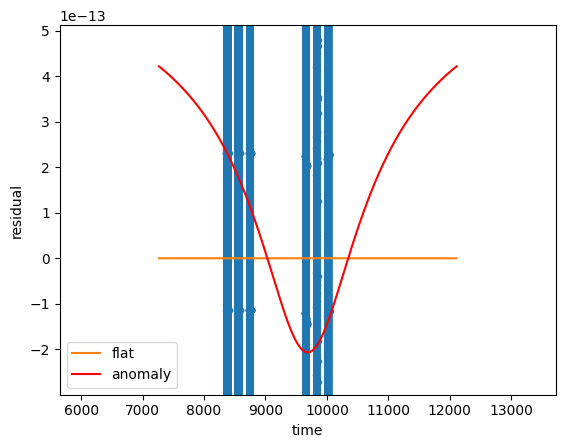

In [8]:
ev.plot_anomaly_window("pspl");

## 4. Save

In [9]:
ev.write_json("event.json");